# EDA workstream E — regions, completeness and discrepancy

Owner: Project 5. Question: where do neurons and synapses sit, how complete is the record, and how often does an edge recur in another copy?

fafb (783) and malecns (v1.0). As the plan's Definitions say, malecns means its brain part: neurons with `in_brain`, the edges among them and, in edgeroi, brain neuropils only. The nerve-cord list passed to `add_provisional_flags` is provisional (`src/eda_e.py`, `MALECNS_NERVE_CORD`). E6 is pending: it needs the hemibrain.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import pandas as pd
from IPython.display import Image, display
from src import fetch_fafb, fetch_malecns
from src import eda_e_figures as F
from src.eda_e import brain_part
fafb = (fetch_fafb.load_neurons(), fetch_fafb.load_edges(), fetch_fafb.load_edgeroi())
mal_edges_all = fetch_malecns.load_edges()
mal = brain_part(fetch_malecns.load_neurons(), mal_edges_all, fetch_malecns.load_edgeroi())
from src.eda_e import columnar_cx_types
FAFB_COLUMNAR = columnar_cx_types(fafb[0])
print('malecns brain part:', [len(t) for t in mal])
STATS = {}

def show(key, result):
    paths, st, tabs = result
    STATS[key] = st
    print(json.dumps(st, indent=1, default=float))
    for p in paths:
        display(Image(filename=str(p)))
    return tabs

malecns brain part: [142621, 21359412, 24242521]


## E1. One neuron, one region (D15, D17)

{
 "neurons": 45168,
 "no_synapses": 318,
 "median_top_share": 0.5601480919796453,
 "gap_below_0.10": 11268,
 "gap_below_0.10_pct": 24.946865037194474
}


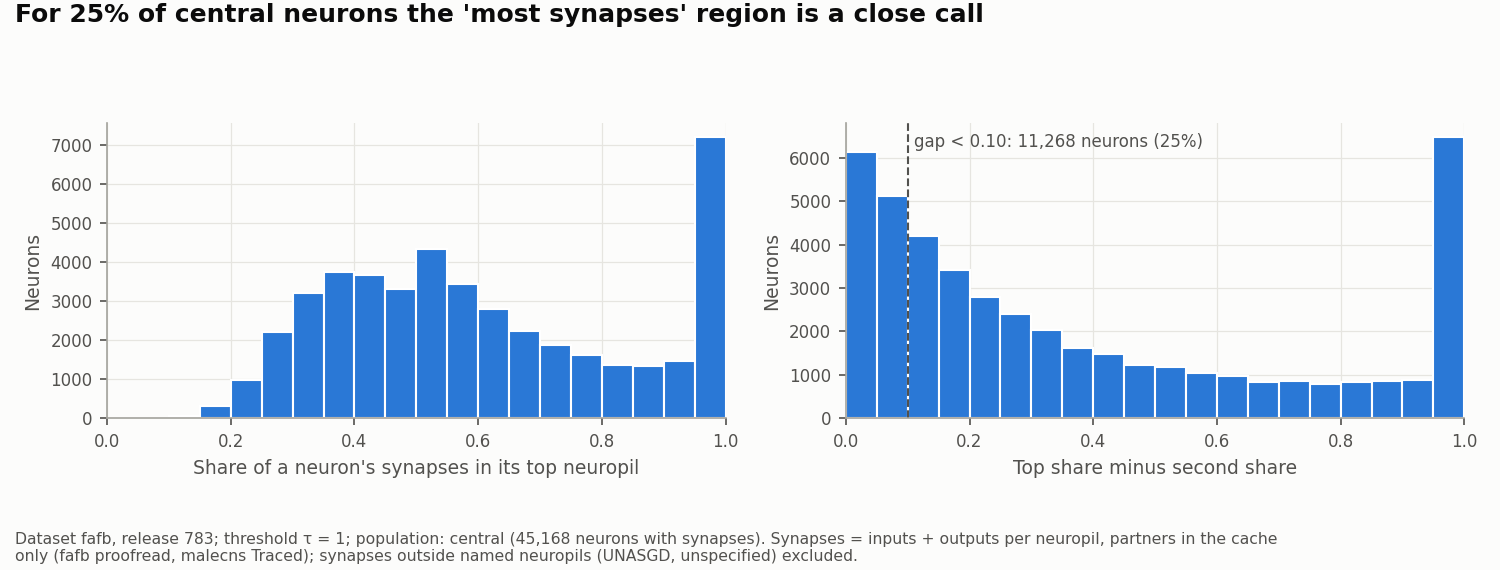

,neuron_id,cell_type,edges,input_synapses,top_frac_in,sum_of_fractions
0,720575940614297640,EPG,before (τ = 1),256,"EB 0.84, PB 0.11, FB 0.02",1.0
1,720575940614297640,EPG,after (τ = 10),32,"EB 0.81, GA_L 0.12, FB 0.06",1.0
2,720575940605213100,JO-DA,before (τ = 1),8,"AMMC_L 0.50, SAD 0.50",1.0
3,720575940605213100,JO-DA,after (τ = 10),0,—,0.0
4,720575940600646173,JO-EV6,before (τ = 1),57,"AMMC_L 0.56, SAD 0.44",1.0
5,720575940600646173,JO-EV6,after (τ = 10),0,—,0.0


In [3]:
tabs = show('E1_fafb', F.fig_e1(*fafb))
display(tabs['worked_example'])

{
 "neurons": 43868,
 "no_synapses": 17,
 "median_top_share": 0.5965643706264228,
 "gap_below_0.10": 8677,
 "gap_below_0.10_pct": 19.779793927236256
}


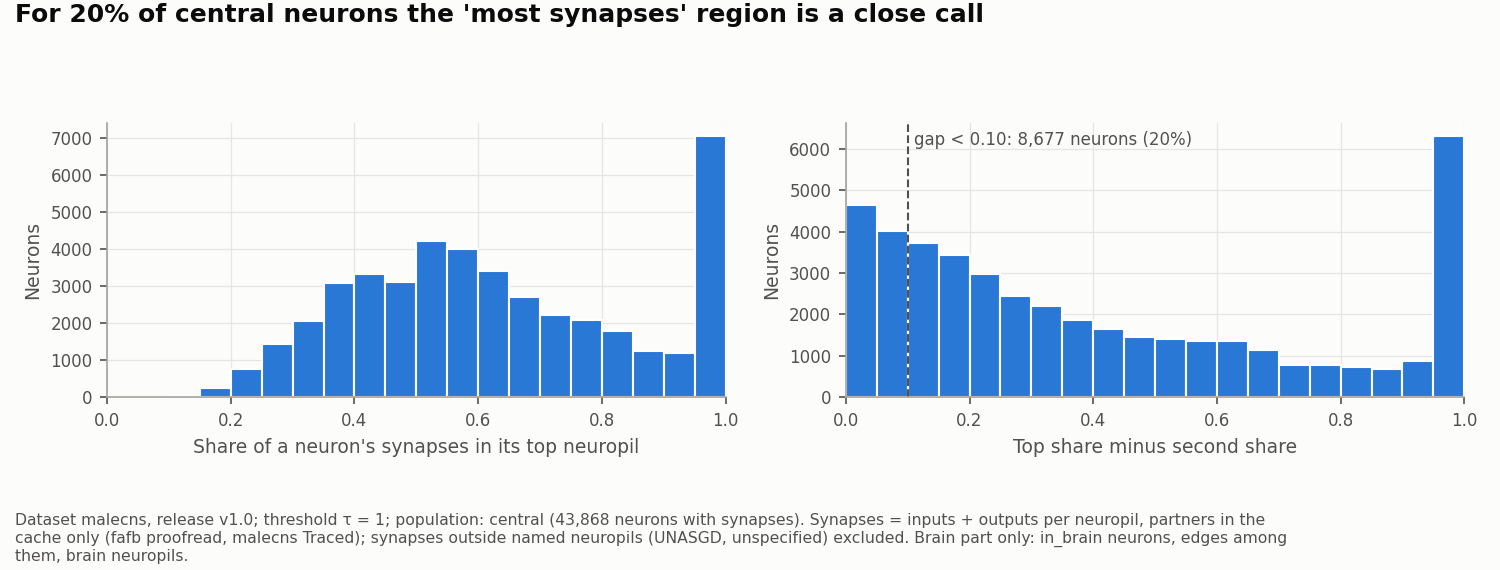

,neuron_id,cell_type,edges,input_synapses,top_frac_in,sum_of_fractions
0,10539,EPG,before (τ = 1),4828,"EB 0.91, PB 0.04, LAL(L) 0.04",1.0
1,10539,EPG,after (τ = 10),3984,"EB 0.92, PB 0.04, LAL(L) 0.04",1.0
2,10434,AN19B019,before (τ = 1),688,"PLP(L) 0.16, SMP(L) 0.13, CRE(L) 0.12",1.0
3,10434,AN19B019,after (τ = 10),255,"PLP(L) 0.16, ICL(L) 0.13, SCL(L) 0.12",1.0
4,13422,CL171,before (τ = 1),107,"ICL(R) 0.70, SPS(R) 0.19, SPS(L) 0.07",1.0
5,13422,CL171,after (τ = 10),0,—,0.0


In [4]:
tabs = show('E1_malecns', F.fig_e1(*mal, ds='malecns', release='v1.0'))
display(tabs['worked_example'])

## E2. The optic-lobe share (D13, D14)

{
 "fafb": {
  "neurons": 139262,
  "clean central": 42100,
  "ambiguous": 5947,
  "clean optic": 90588,
  "no synapses": 627,
  "optic_by_super_class_pct": 55.679941405408506,
  "optic_by_region_flag_pct": 67.33782367049159,
  "optic_by_synapse_share_pct": 65.04861340494894,
  "ambiguous_pct": 4.270368083181342
 },
 "malecns": {
  "neurons": 142621,
  "clean central": 39568,
  "ambiguous": 6504,
  "clean optic": 96443,
  "no synapses": 106,
  "optic_by_super_class_pct": 62.67239747302291,
  "optic_by_region_flag_pct": 69.22963658928208,
  "optic_by_synapse_share_pct": 67.62187896593068,
  "ambiguous_pct": 4.560338239109248
 }
}


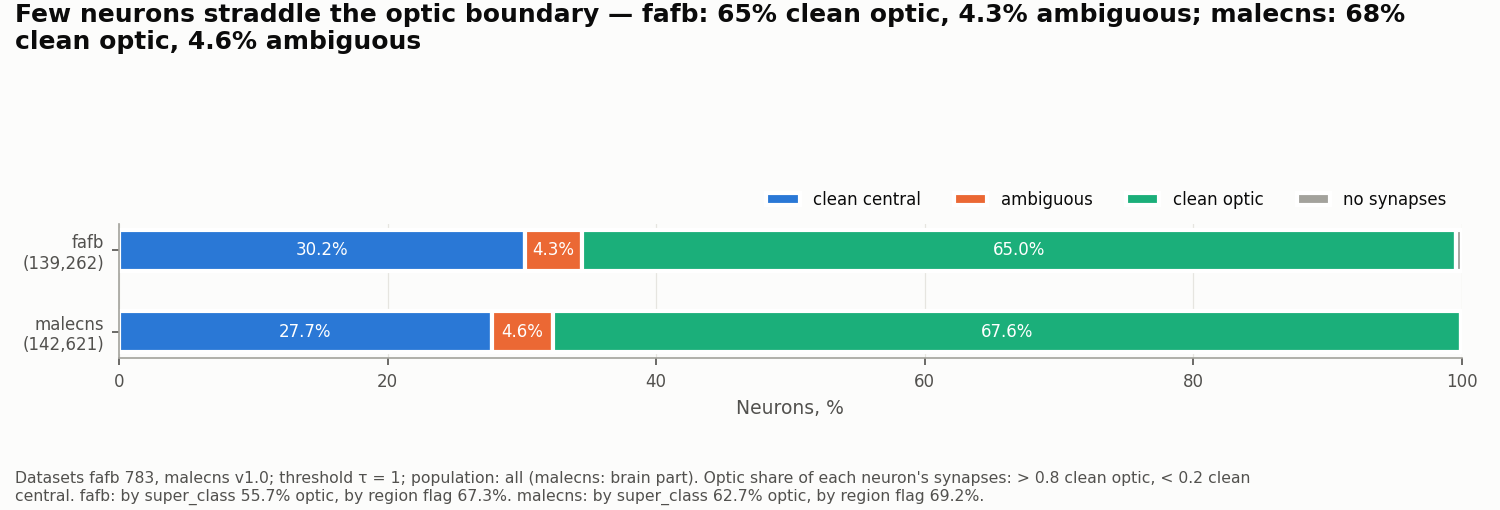

In [5]:
show('E2', F.fig_e2({'fafb': ('783', fafb[0], fafb[2]), 'malecns': ('v1.0', mal[0], mal[2])}));

## E3. The region-to-region map

{
 "fafb": {
  "regions": 38,
  "within_region_share": 0.5938392332902658,
  "synapses": 13378205
 },
 "malecns": {
  "regions": 35,
  "within_region_share": 0.6039540469716121,
  "synapses": 28280443
 }
}


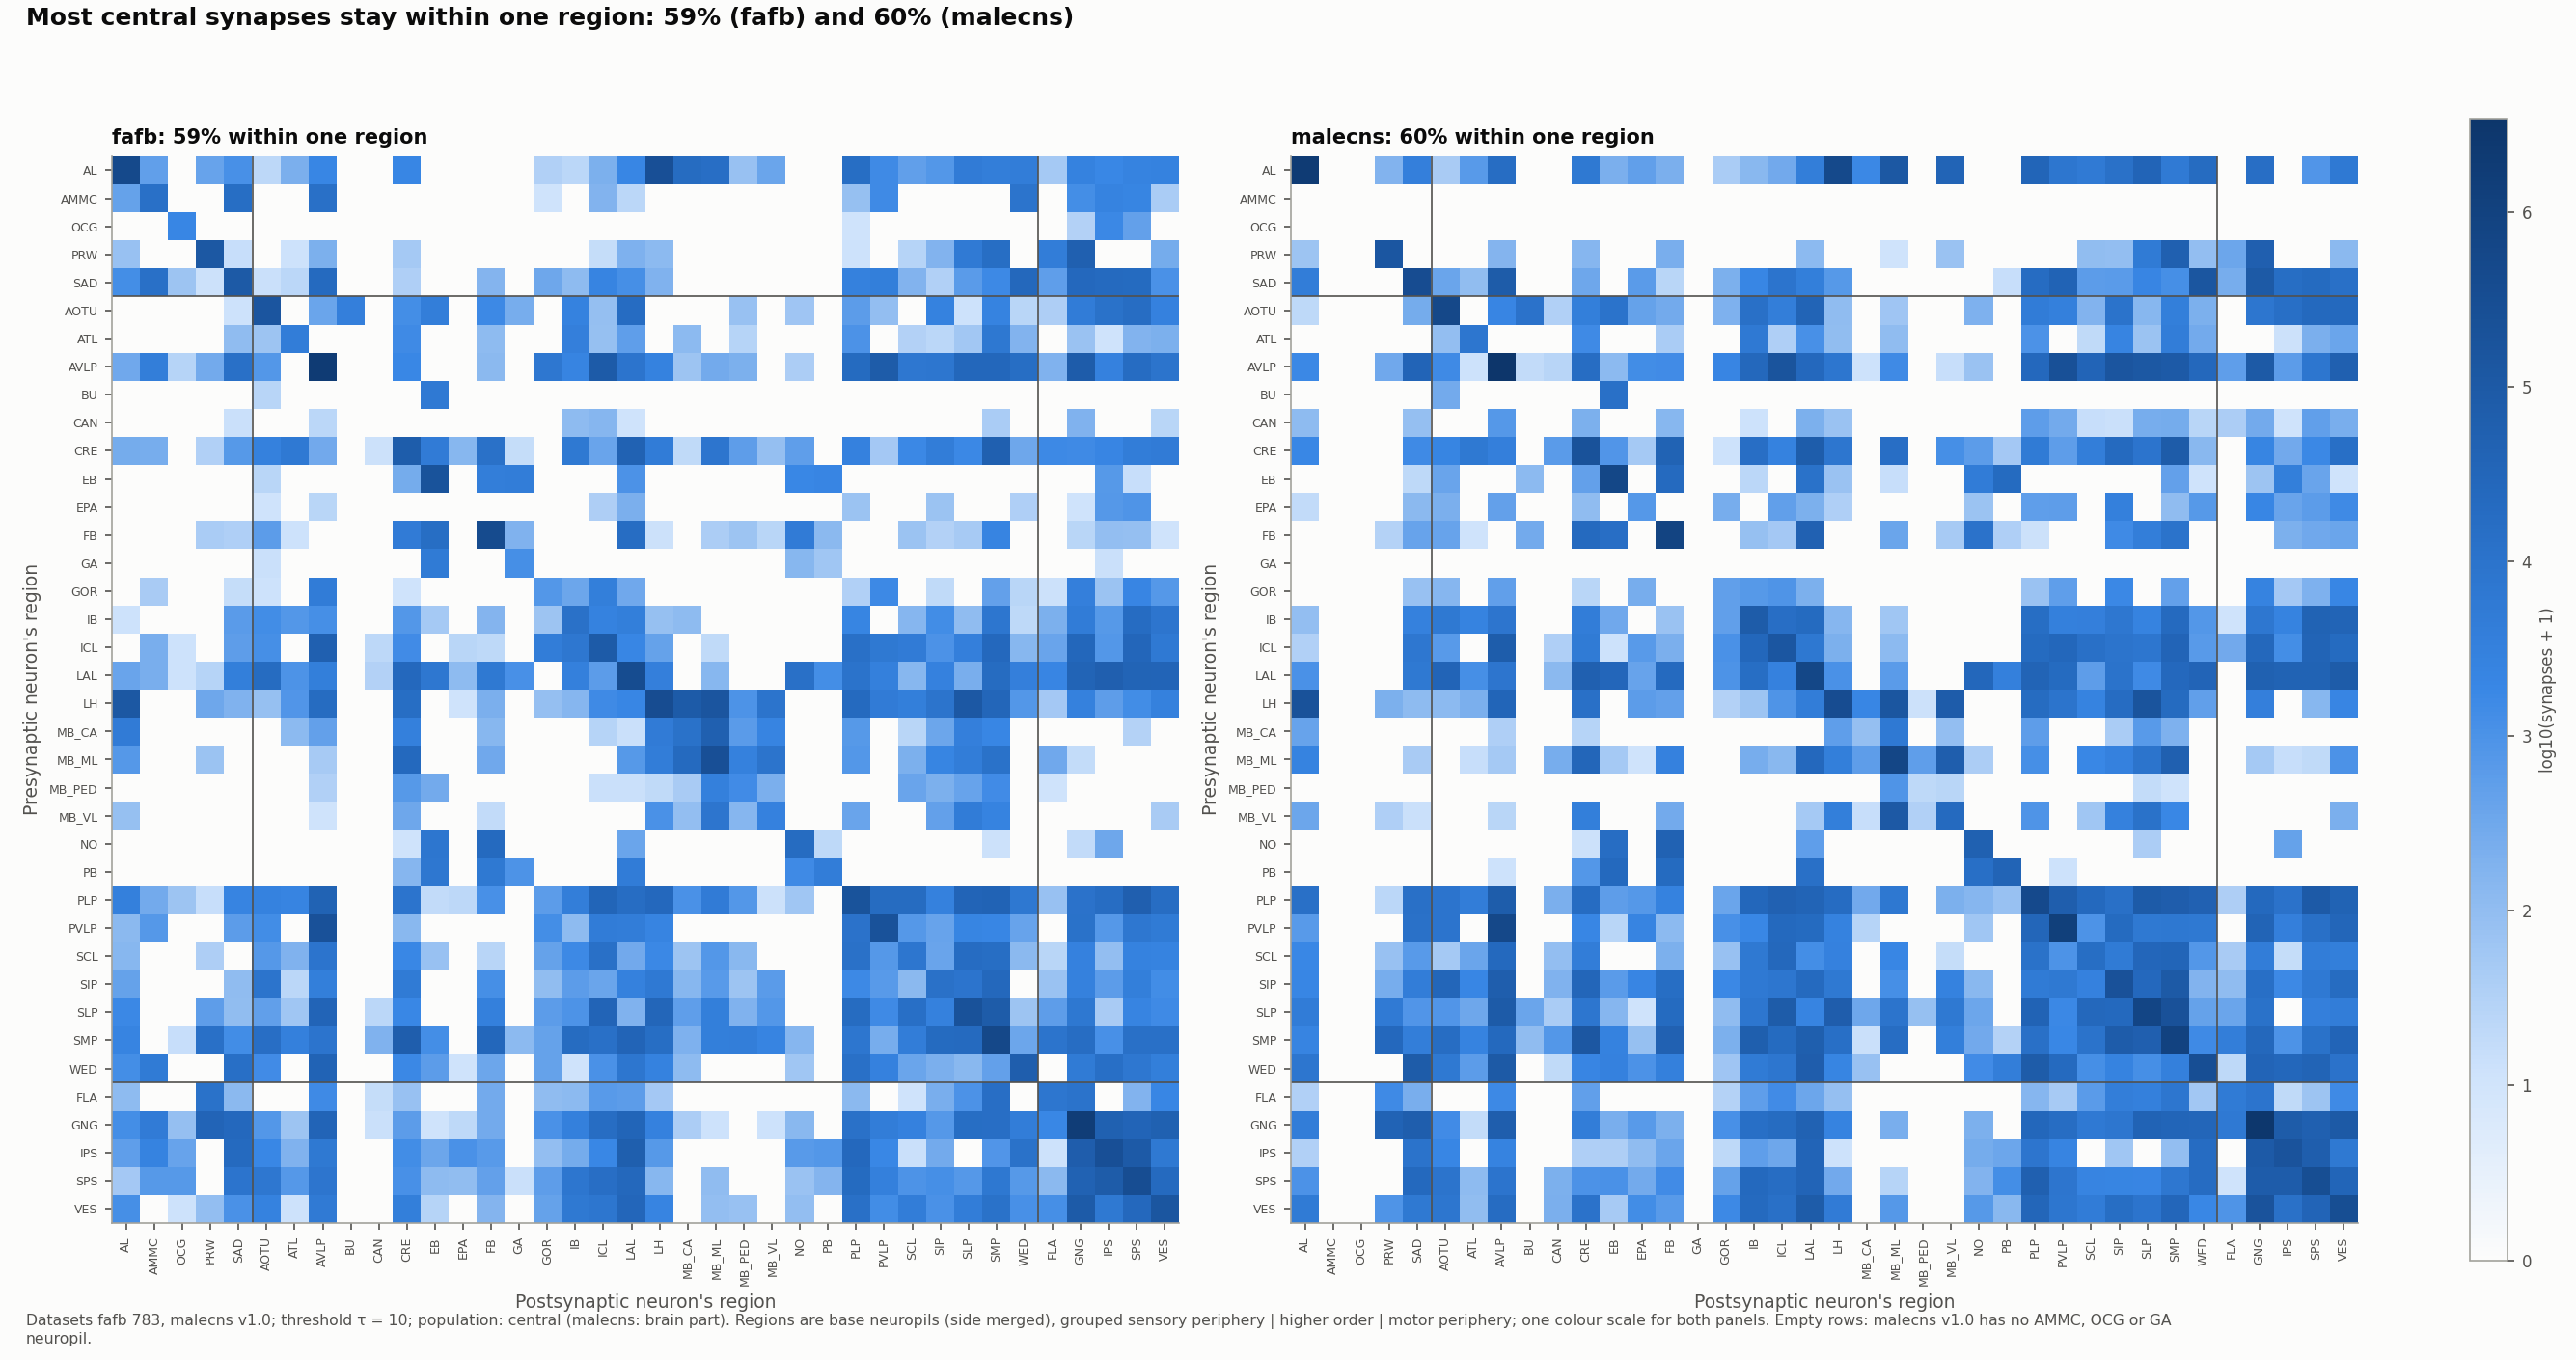

In [6]:
show('E3', F.fig_e3({'fafb': ('783', fafb[0], fafb[1]), 'malecns': ('v1.0', mal[0], mal[1])}));

## E4. How complete is each neuron's record

{
 "neurons": 43882,
 "median_ratio": 0.9612101649233831,
 "pooled_ratio": 0.9526921734083773,
 "over_1": 0,
 "below_0.5": 377,
 "median_ratio_brain_partners": 0.9558801534373845,
 "pooled_ratio_brain_partners": 0.9116365961688152,
 "median_ratio_ascending_brain_partners": 0.2689401241847015
}


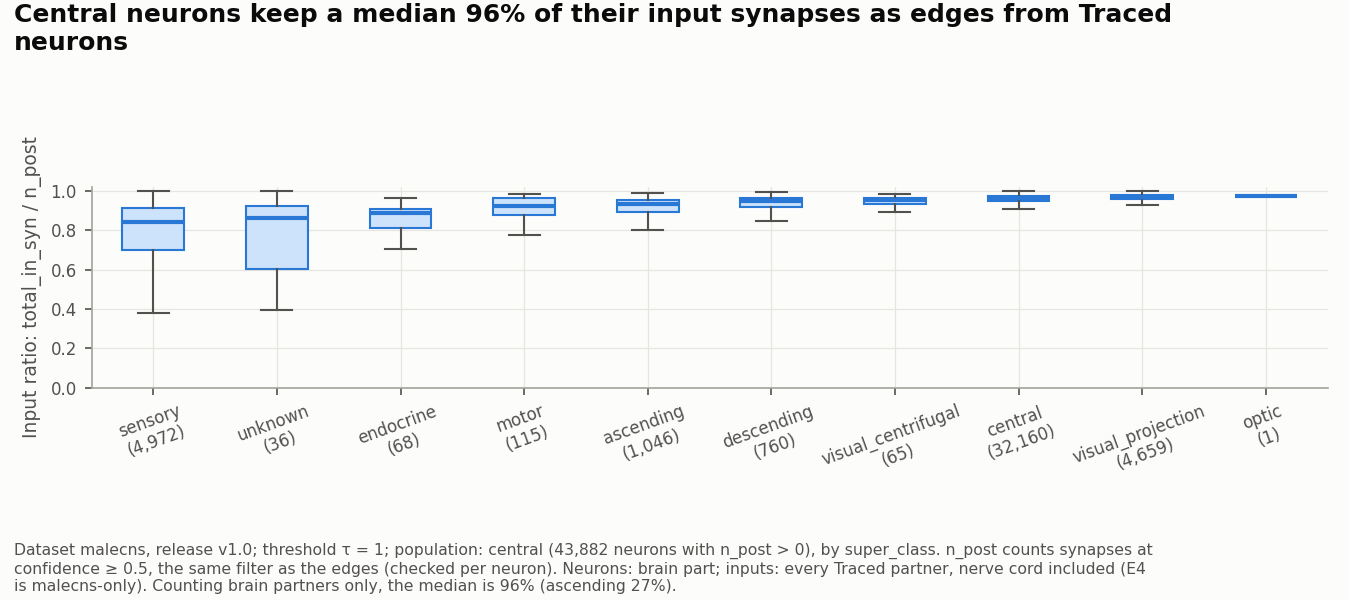

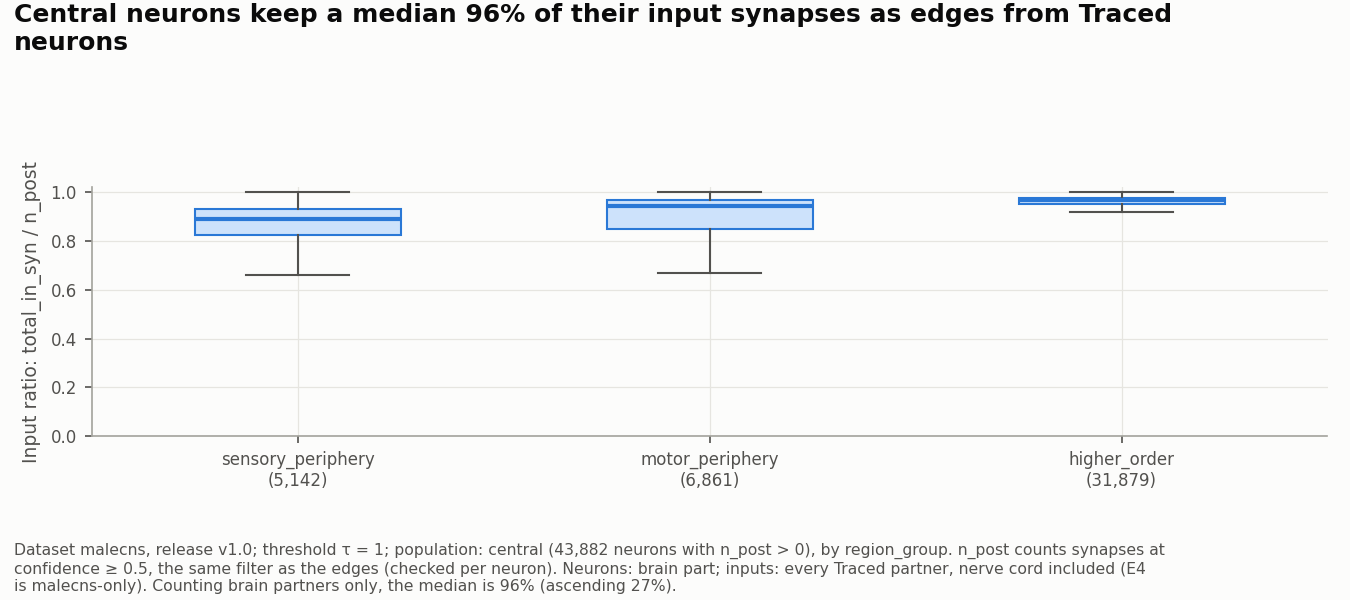

In [7]:
# The plan's E4 (malecns). n_post was checked to count only synapses at confidence >= 0.5.
# Inputs from every Traced partner (E4 is malecns-only, so the brain-part rule's reason does not apply).
show('E4_malecns', F.fig_e4_malecns(mal[0], mal_edges_all, mal[1]));

{
 "neurons": 45109,
 "median_ratio": 0.9516129032258065,
 "pooled_ratio": 0.9508321025098919,
 "over_1": 0
}


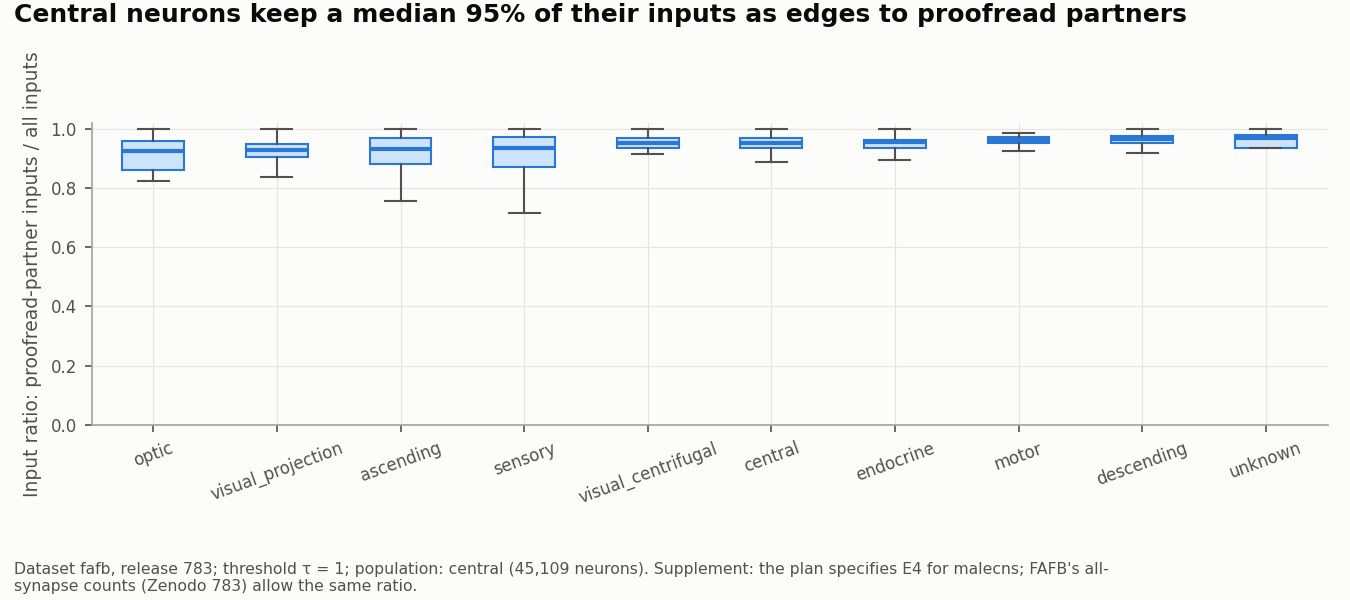

In [8]:
# FAFB supplement: FlyWire's all-synapse counts allow the same ratio.
show('E4supp_fafb', F.fig_e4_fafb(fafb[0], fafb[1], pd.read_feather(fetch_fafb.raw_file('neuropil_post'))));

## E5. Does an edge recur on the other side (D10)

{
 "central": {
  "type_pairs": 1656860,
  "share_1syn": 0.3151210402960113,
  "share_10plus": 0.9622144006192774
 },
 "optic": {
  "type_pairs": 87960,
  "share_1syn": 0.4606385474854796,
  "share_10plus": 0.9744367417677643
 }
}


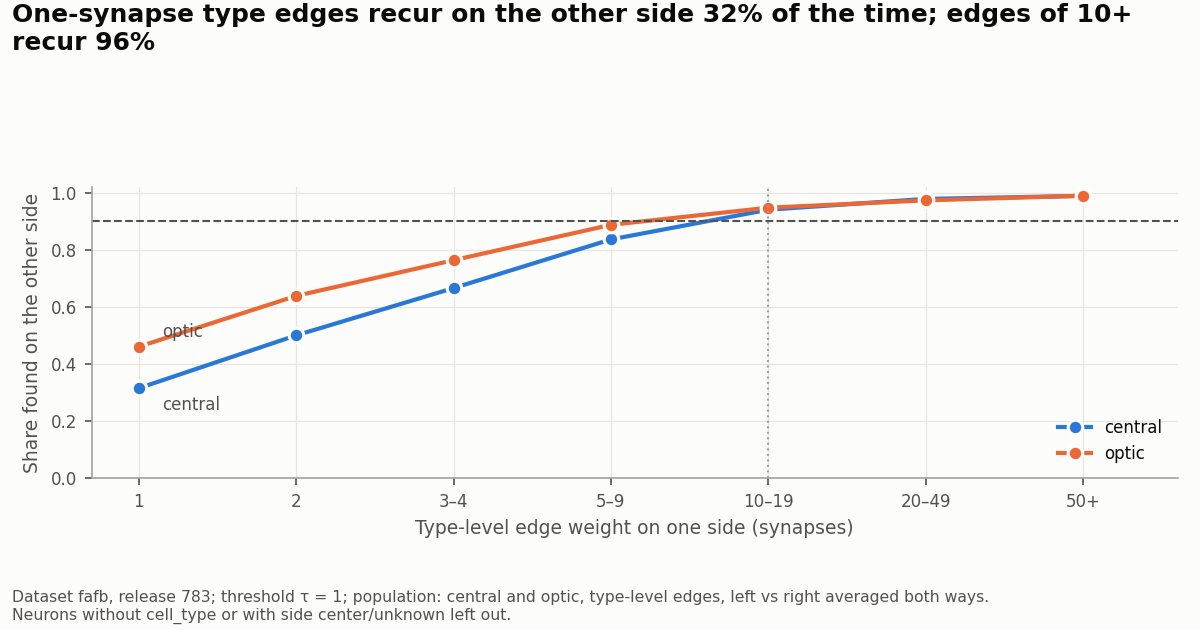

central                         optic                       
        share pairs_left pairs_right  share pairs_left pairs_right
bin                                                               
1       0.315     499460      511873  0.461      15254       15074
2       0.500     178810      185746  0.639       7849        7695
3–4     0.666     150294      158536  0.764       9010        8449
5–9     0.837     127035      137096  0.888      10341        9970
10–19   0.941      76172       84060  0.948       8399        8208
20–49   0.979      53294       59349  0.974       8692        8534
50+     0.990      27366       30467  0.990      13846       14637

,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
min side count 0,23212,0.000,0.000,0.000,0.000,0.000,0.000,0.000
min side count 1,1327266,0.312,0.500,0.668,0.841,0.949,0.986,0.996
2–4,297250,0.346,0.530,0.690,0.858,0.952,0.988,0.997
5–19,8699,0.418,0.605,0.749,0.876,0.956,0.976,0.995
20+,433,0.557,0.735,0.837,0.948,0.987,1.000,1.000


,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
all types,1656860,0.315,0.500,0.666,0.837,0.941,0.979,0.990
both types on both sides,1633648,0.319,0.506,0.673,0.845,0.950,0.987,0.996
equal left/right counts,1059871,0.320,0.514,0.686,0.860,0.961,0.991,0.999
"hemibrain-matched, both sides",843048,0.327,0.516,0.684,0.856,0.956,0.989,0.997


In [9]:
tabs = show('E5_fafb', F.fig_e5(fafb[0], fafb[1]))
display(pd.concat(tabs, axis=1).round(3))
from src.eda_e import e5_by_type_size, e5_restricted
display(e5_by_type_size(fafb[0], fafb[1]))  # recurrence rises with type size
display(e5_restricted(fafb[0], fafb[1]))    # restricting the type set barely moves it

{
 "central": {
  "type_pairs": 1933642,
  "share_1syn": 0.3243717895920865,
  "share_10plus": 0.9471728408309587
 },
 "optic": {
  "type_pairs": 88010,
  "share_1syn": 0.44690692496328893,
  "share_10plus": 0.9572361017330633
 }
}


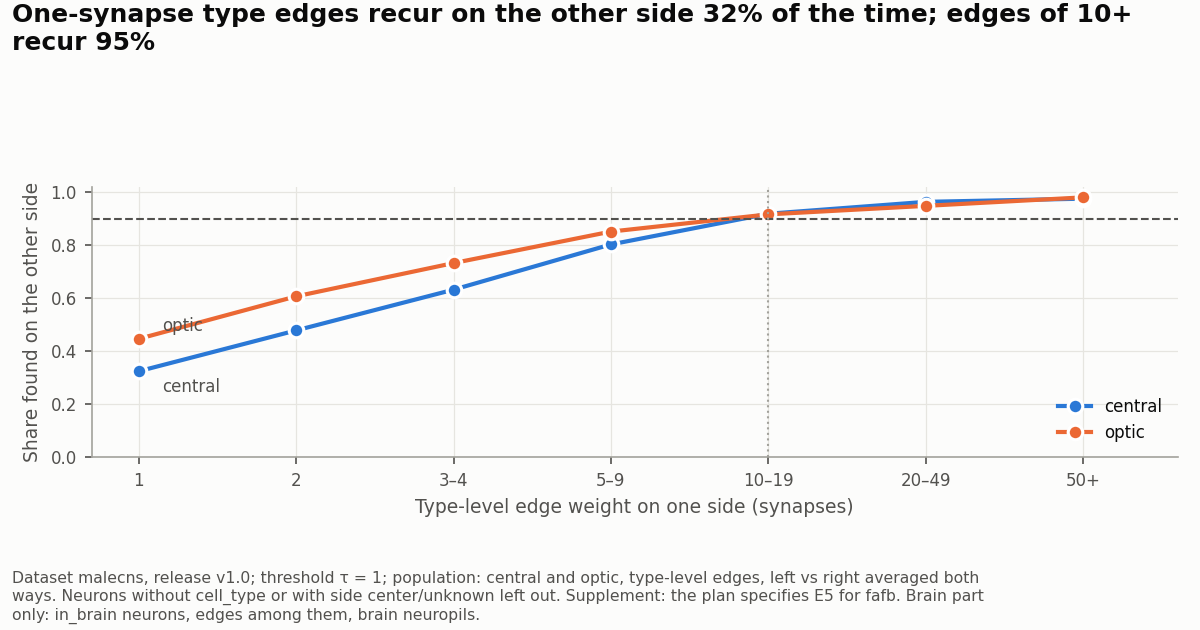

central                         optic                       
        share pairs_left pairs_right  share pairs_left pairs_right
bin                                                               
1       0.324     503969      513827  0.447      13193       14433
2       0.479     219171      221668  0.607       6992        7595
3–4     0.633     195962      199263  0.733       8034        8622
5–9     0.804     174251      177519  0.852       9425        9815
10–19   0.920     109738      114261  0.917       8079        8294
20–49   0.965      84139       87885  0.949       8239        8763
50+     0.977      51764       55439  0.982      15808       17462

,type_pairs,1,2,3–4,5–9,10–19,20–49,50+
min side count 0,59506,0.000,0.000,0.000,0.000,0.000,0.000,0.000
min side count 1,1446702,0.324,0.482,0.641,0.819,0.938,0.984,0.996
2–4,411325,0.357,0.511,0.666,0.832,0.943,0.986,0.996
5–19,15508,0.424,0.576,0.719,0.844,0.946,0.980,0.997
20+,601,0.630,0.678,0.800,0.929,0.973,0.979,1.000


In [10]:
# malecns supplement (the plan specifies E5 for fafb): the male's own left-right curve
tabs = show('E5supp_malecns', F.fig_e5(mal[0], mal[1], 'malecns', 'v1.0', item='E5supp',
            note='Supplement: the plan specifies E5 for fafb. ' + F.BRAIN_NOTE['malecns']))
display(pd.concat(tabs, axis=1).round(3))
display(e5_by_type_size(mal[0], mal[1]))

## E6. Does an edge recur in another animal

Pending: needs the hemibrain v1.2.1 (bulk files or a neuPrint token).

## E7. Central complex profile

{
 "fafb": {
  "PB": 100,
  "FB": 1896,
  "EB": 397,
  "NO": 224
 },
 "malecns": {
  "PB": 87,
  "FB": 1887,
  "EB": 419,
  "NO": 265
 }
}


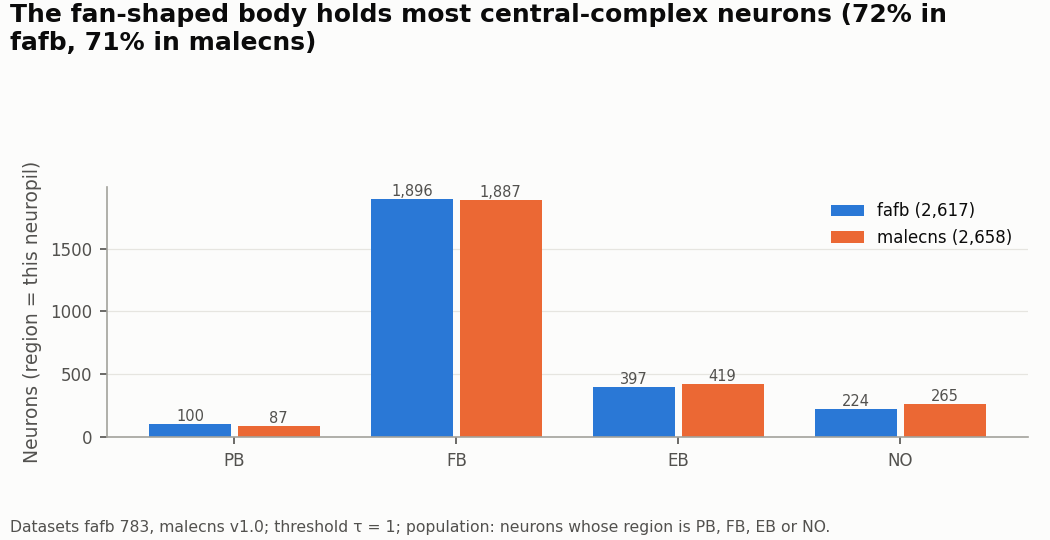

In [11]:
show('E7a', F.fig_e7a({'fafb': ('783', fafb[0]), 'malecns': ('v1.0', mal[0])}));

{
 "neurons_region_cx": 2617,
 "neurons_cell_class_cx": 2875,
 "overlap": 2560,
 "cell_types": 223,
 "untyped": 10,
 "types_8_to_16_on_both_sides": 31,
 "types_one_on_both_sides": 53,
 "edges_at_tau": 66982,
 "columnar_neurons": 1224,
 "columnar_block_fill_median": 0.02506265664160401,
 "columnar_connected_type_pairs": 393
}


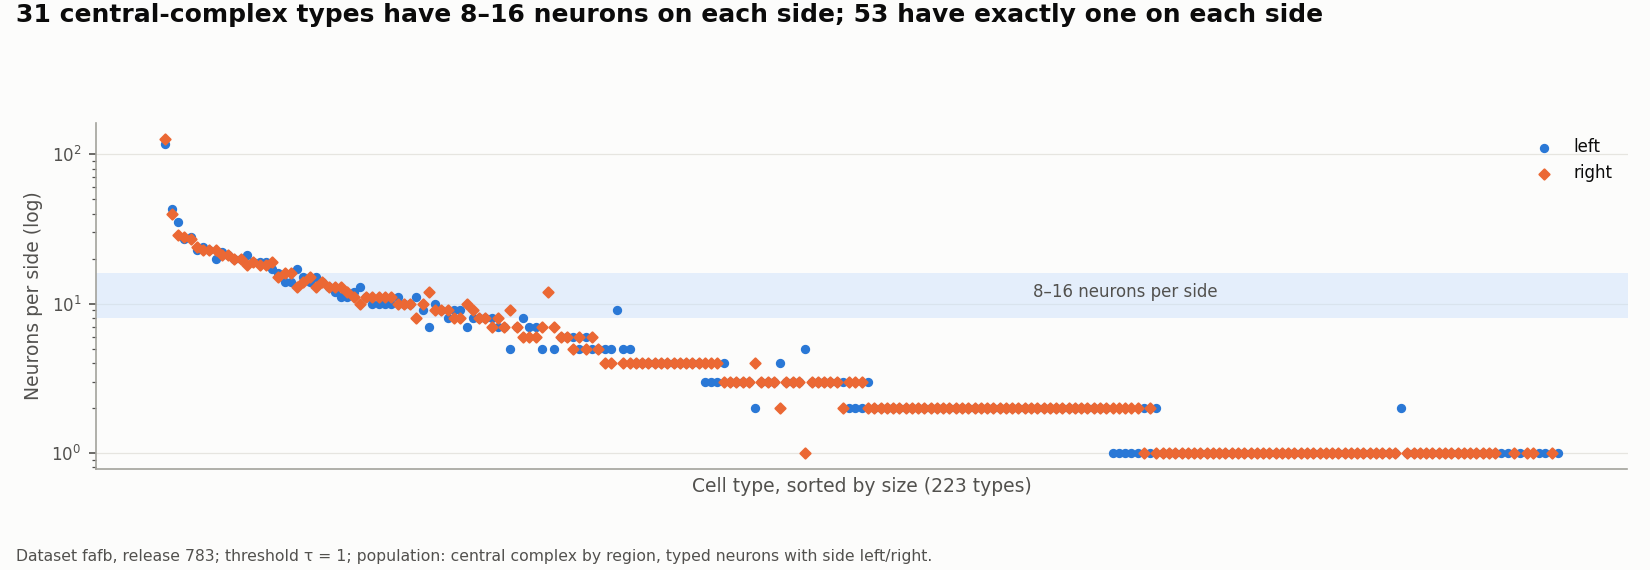

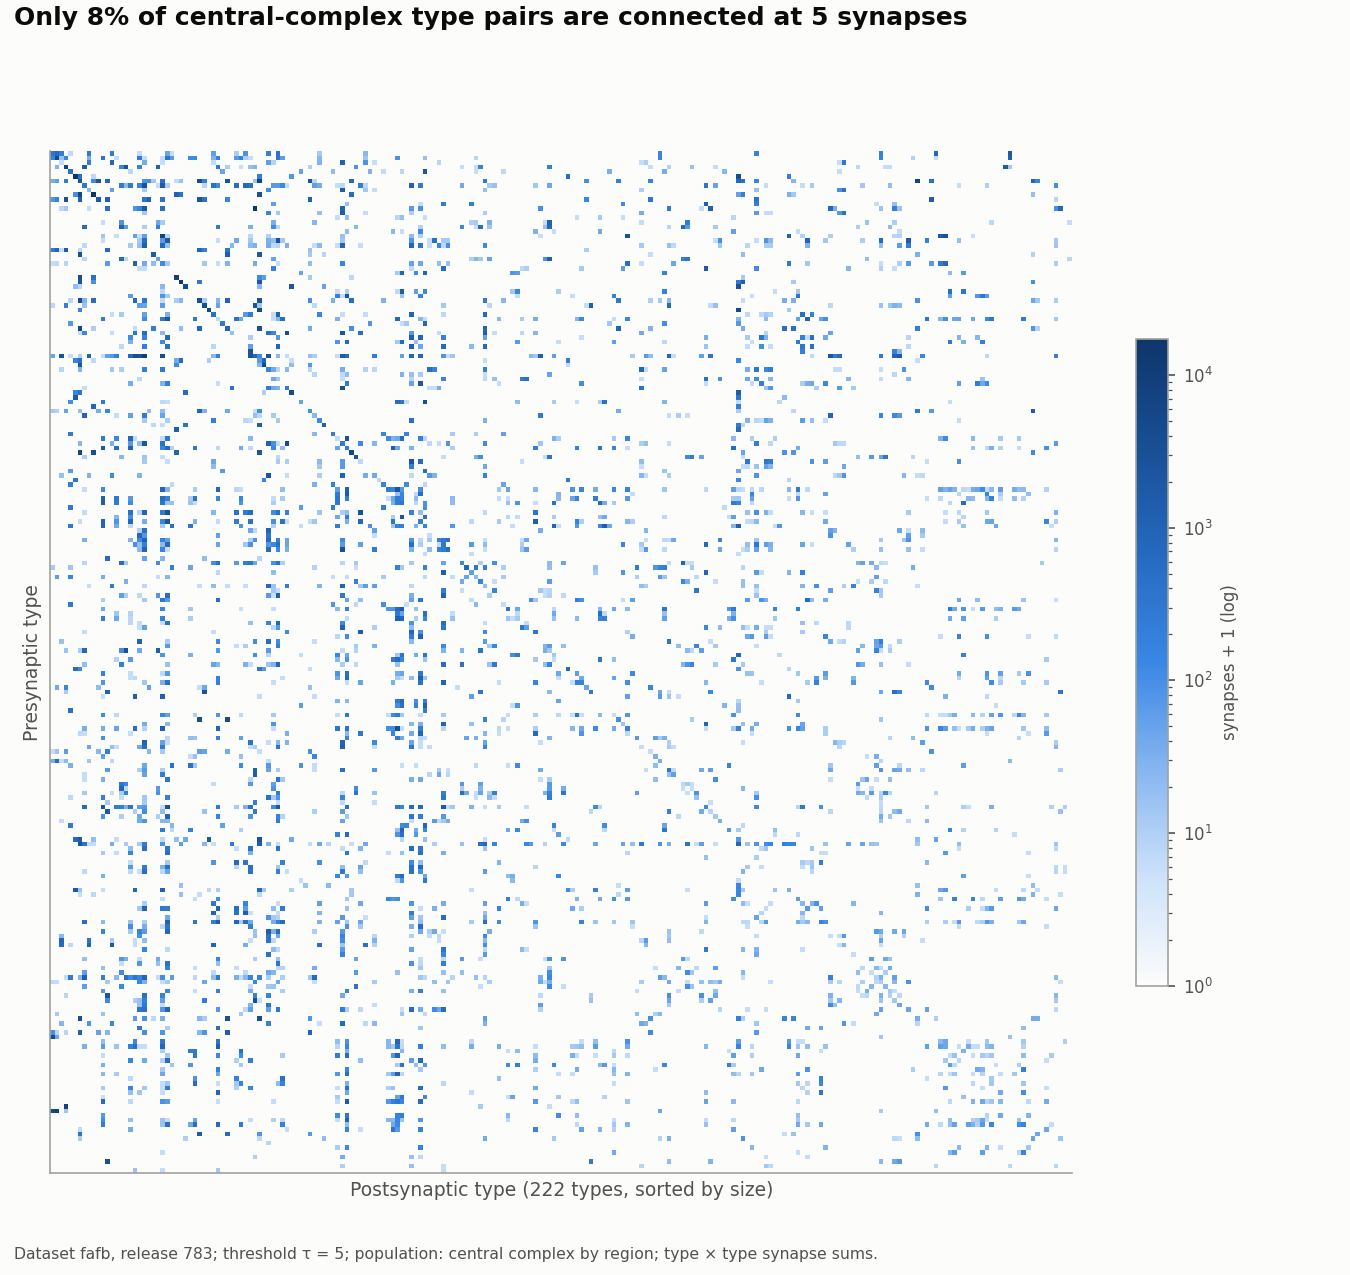

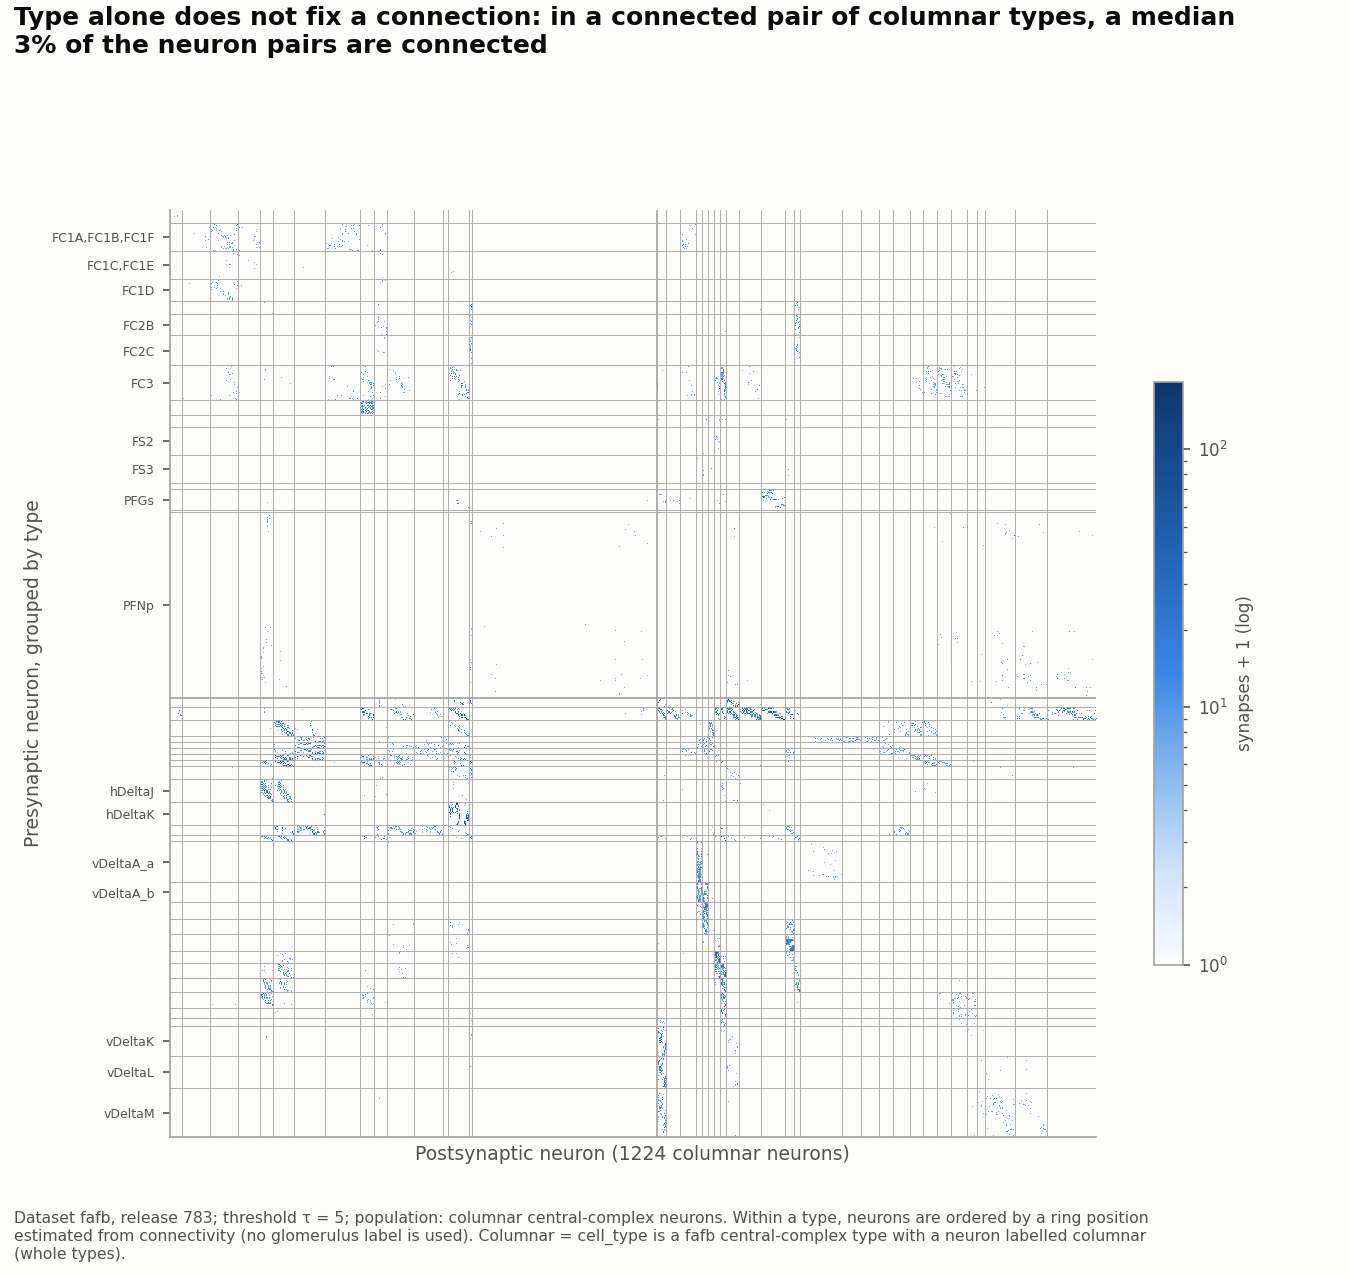

In [12]:
show('E7_fafb', F.fig_e7(fafb[0], fafb[1], FAFB_COLUMNAR));

{
 "neurons_region_cx": 2658,
 "neurons_cell_class_cx": 2950,
 "overlap": 2628,
 "cell_types": 283,
 "untyped": 1,
 "types_8_to_16_on_both_sides": 37,
 "types_one_on_both_sides": 81,
 "edges_at_tau": 127740,
 "columnar_neurons": 1311,
 "columnar_block_fill_median": 0.022222222222222223,
 "columnar_connected_type_pairs": 678
}


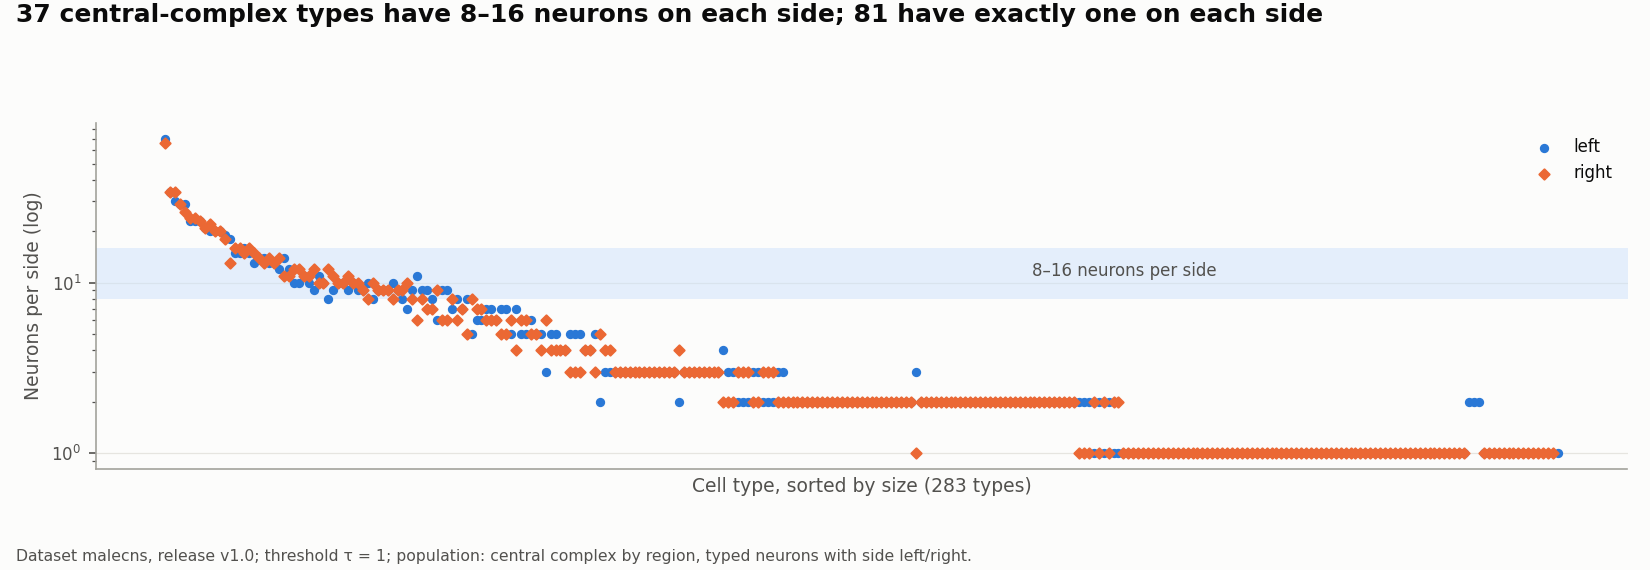

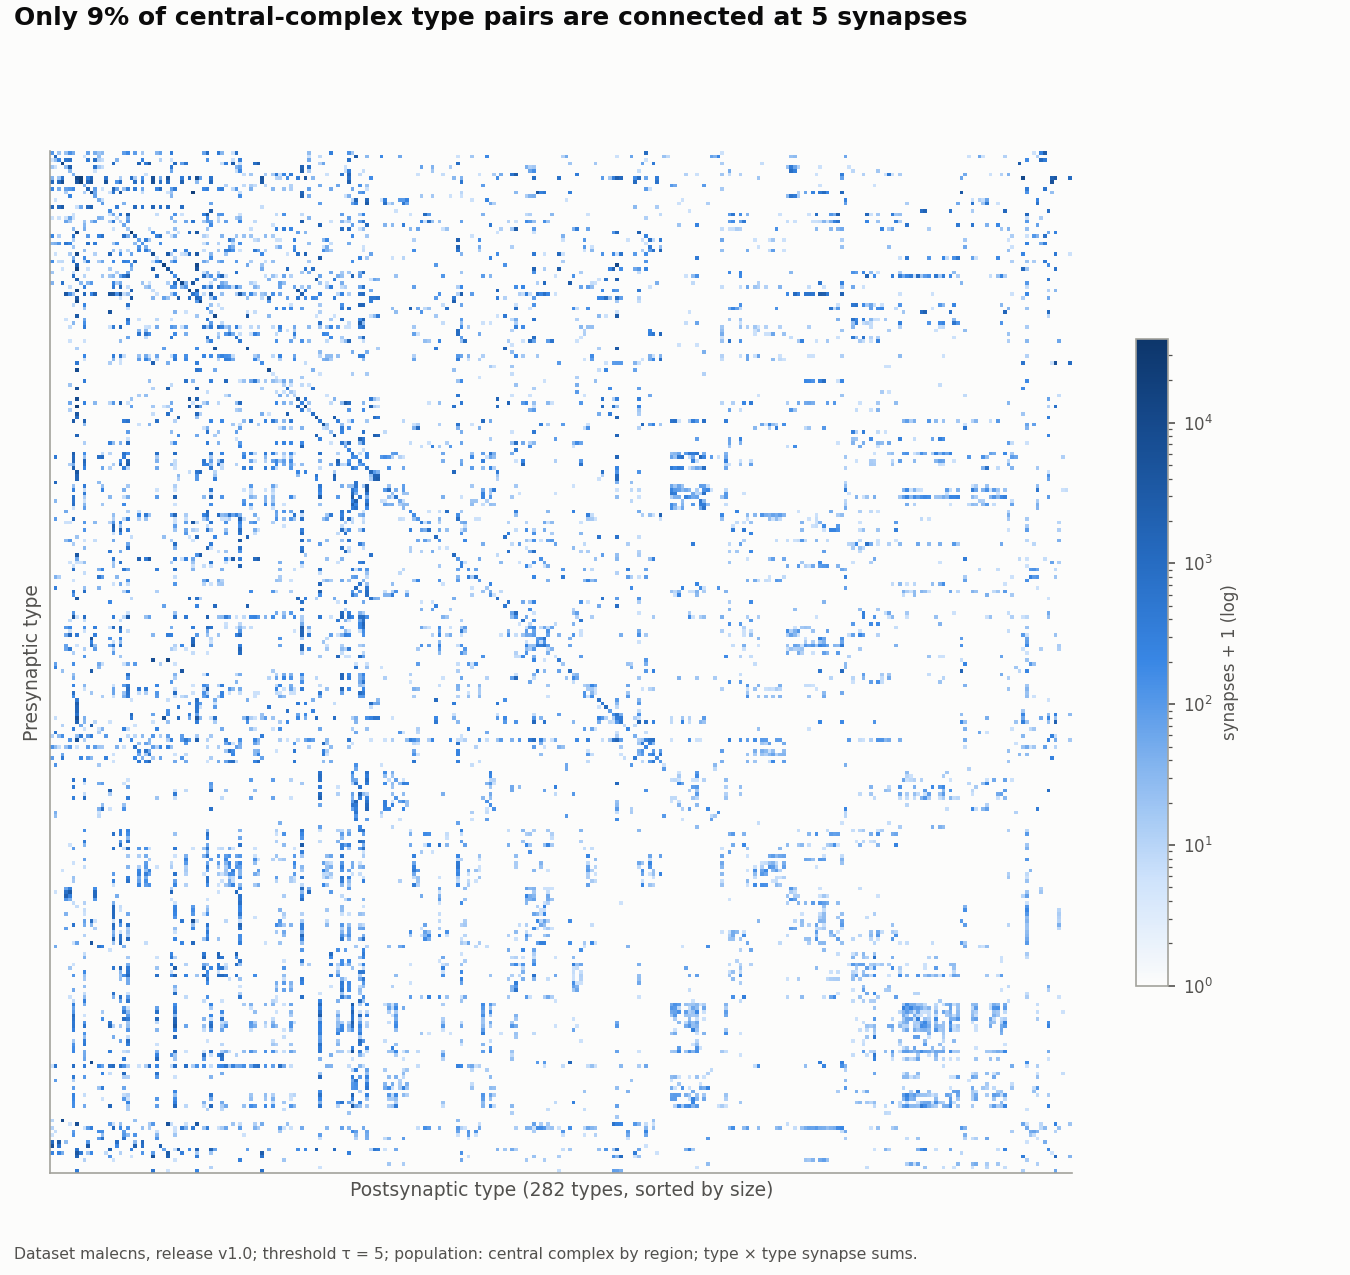

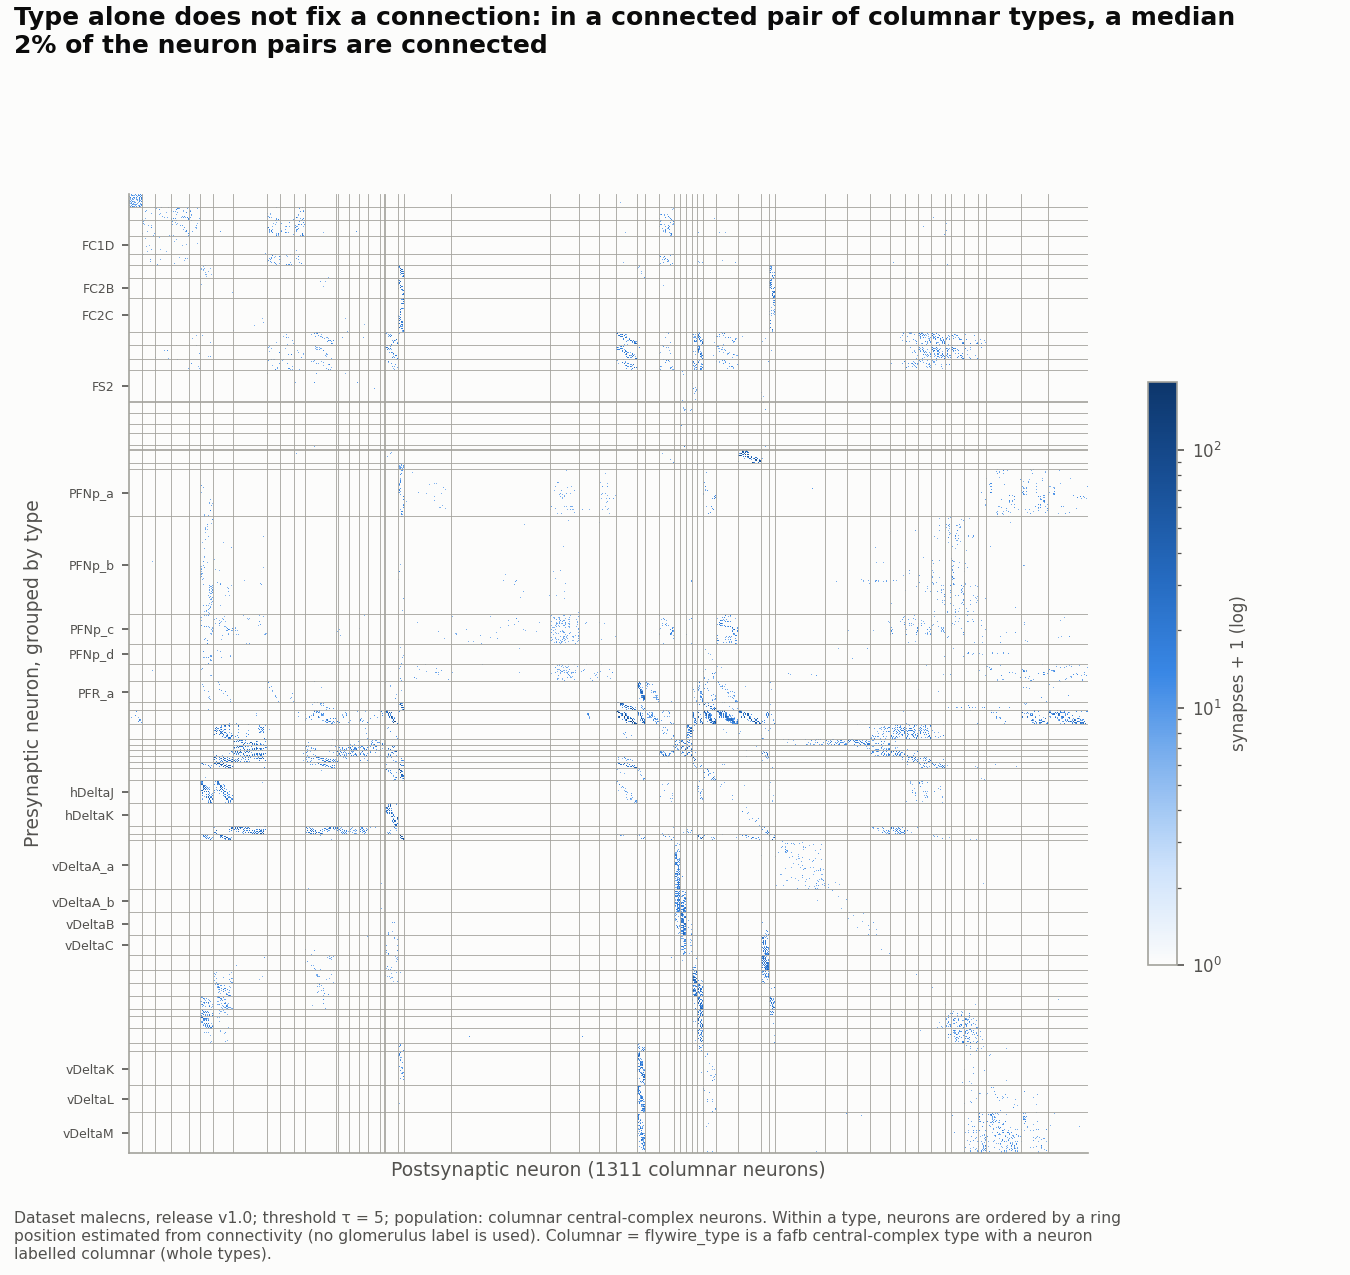

In [13]:
show('E7_malecns', F.fig_e7(mal[0], mal[1], FAFB_COLUMNAR, 'malecns', 'v1.0', type_column='flywire_type'));

In [14]:
(ROOT / 'reports' / 'eda_E_stats.json').write_text(json.dumps(STATS, indent=1, default=float))

3079